<a href="https://colab.research.google.com/github/Ankurchatterjee-me/DataScienceProject/blob/main/AIOps_smd_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Configuration (edit only this cell if you need to)
SEED = 42
RUN_MODE = "FULL"          # "FULL" (default study) or "SMOKE"
SMOKE_MACHINES = ["machine-1-1", "machine-1-2"]
RUN_TRANSFER = False       # optional extra experiment; leave False for the official protocol
KAGGLE_HANDLE = "mgusat/smd-onmiad"


In [2]:
# If a line starts with % or !, it is a notebook shortcut, not ordinary Python.
%pip install -q kagglehub scikit-learn pandas numpy matplotlib


In [3]:
"""SMD per-machine detection helpers.

The Colab notebook copies this logic so it can run after a single upload
without importing this file. Local smoke tests may import it directly.
"""

from __future__ import annotations

import hashlib
import json
import os
import re
import shutil
import subprocess
import sys
import traceback
import zipfile
from dataclasses import asdict, dataclass, field
from datetime import datetime, timezone
from pathlib import Path
from typing import Any, Iterable

import numpy as np
import pandas as pd

SEED = 42
N_FEATURES = 38
N_MACHINES_EXPECTED = 28
FIT_FRACTION = 0.80
THRESHOLD_PERCENTILE = 99.5
MIN_CALIBRATION_ROWS = 20
EPS = 1e-12
SMOKE_MACHINES_DEFAULT = ["machine-1-1", "machine-1-2"]
MACHINE_RE = re.compile(r"^(machine-\d+-\d+)\.txt$")
KAGGLE_HANDLE = "mgusat/smd-onmiad"
GITHUB_REPO = "https://github.com/NetManAIOps/OmniAnomaly.git"


def set_global_seed(seed: int = SEED) -> None:
    np.random.seed(seed)


def sha256_file(path: Path, chunk: int = 1024 * 1024) -> str:
    h = hashlib.sha256()
    with path.open("rb") as f:
        while True:
            block = f.read(chunk)
            if not block:
                break
            h.update(block)
    return h.hexdigest()


def discover_dataset_root(start_paths: Iterable[Path]) -> Path | None:
    """Find a folder that contains train/, test/, and test_label/ machine files."""
    seen: set[Path] = set()
    queue: list[Path] = []
    for raw in start_paths:
        if raw is None:
            continue
        p = Path(raw).expanduser().resolve() if Path(raw).exists() else Path(raw)
        if p.exists():
            queue.append(p)
    while queue:
        cur = queue.pop(0)
        try:
            cur = cur.resolve()
        except OSError:
            continue
        if cur in seen:
            continue
        seen.add(cur)
        if cur.is_file():
            continue
        train, test, labels = cur / "train", cur / "test", cur / "test_label"
        if train.is_dir() and test.is_dir() and labels.is_dir():
            if any(MACHINE_RE.match(x.name) for x in train.glob("machine-*.txt")):
                return cur
        try:
            children = list(cur.iterdir())
        except OSError:
            continue
        # Prefer likely names first
        children.sort(key=lambda x: (0 if x.name in {"ServerMachineDataset", "train"} else 1, x.name))
        for child in children:
            if child.is_dir() and child.name not in {".git", "__pycache__", "outputs"}:
                if len(seen) < 400:
                    queue.append(child)
    return None


def list_machines(root: Path) -> list[str]:
    names = []
    for p in sorted((root / "train").glob("machine-*.txt")):
        m = MACHINE_RE.match(p.name)
        if m:
            names.append(m.group(1))
    return names


def load_numeric_matrix(path: Path) -> np.ndarray:
    data = np.loadtxt(path, delimiter=",", dtype=np.float64)
    if data.ndim == 1:
        data = data.reshape(1, -1)
    if data.shape[1] != N_FEATURES:
        raise ValueError(f"{path} has {data.shape[1]} columns; expected {N_FEATURES}")
    return data


def load_binary_labels(path: Path) -> np.ndarray:
    raw = np.loadtxt(path, dtype=np.float64)
    if raw.ndim != 1:
        raw = raw.reshape(-1)
    if not np.all(np.isin(raw, [0.0, 1.0])):
        uniq = np.unique(raw)
        raise ValueError(f"{path} has non-binary labels: {uniq[:10]}")
    return raw.astype(np.int32)


@dataclass
class InterpSpan:
    start: int
    end: int
    dims_1based: list[int]
    raw_line: str
    valid: bool
    error: str | None = None


def parse_interpretation_file(path: Path | None, n_test: int) -> tuple[list[InterpSpan], list[str]]:
    notes: list[str] = []
    spans: list[InterpSpan] = []
    if path is None or not path.exists():
        notes.append("interpretation file missing")
        return spans, notes
    text = path.read_text(encoding="utf-8", errors="replace")
    for raw_line in text.splitlines():
        line = raw_line.strip()
        if not line:
            continue
        try:
            if ":" not in line:
                raise ValueError("missing ':' separator")
            left, right = line.split(":", 1)
            if "-" not in left:
                raise ValueError("missing '-' in range")
            a_str, b_str = left.split("-", 1)
            start, end = int(a_str), int(b_str)
            if start >= end:
                raise ValueError(f"start {start} is not < end {end}")
            if start < 0 or end > n_test:
                raise ValueError(f"range [{start}, {end}) outside test length {n_test}")
            dims: list[int] = []
            for part in right.split(","):
                part = part.strip()
                if not part:
                    continue
                d = int(part)
                if d < 1 or d > N_FEATURES:
                    raise ValueError(f"dimension {d} not in 1..{N_FEATURES}")
                dims.append(d)
            if not dims:
                raise ValueError("no valid dimension IDs")
            spans.append(
                InterpSpan(
                    start=start,
                    end=end,
                    dims_1based=dims,
                    raw_line=line,
                    valid=True,
                )
            )
        except Exception as exc:  # noqa: BLE001 — record and continue
            spans.append(
                InterpSpan(
                    start=-1,
                    end=-1,
                    dims_1based=[],
                    raw_line=line,
                    valid=False,
                    error=str(exc),
                )
            )
            notes.append(f"invalid interpretation line '{line}': {exc}")
    return spans, notes


def chronological_fit_cal_split(n: int) -> tuple[int, int, str]:
    """Return (n_fit, n_cal, threshold_source)."""
    n_fit = int(np.floor(n * FIT_FRACTION))
    n_cal = n - n_fit
    if n_cal < MIN_CALIBRATION_ROWS:
        return n, 0, "fit_fallback"
    if n_fit < 10:
        return n, 0, "fit_fallback"
    return n_fit, n_cal, "calibration_99_5"


def fit_imputer_and_scaler(X_fit: np.ndarray) -> dict[str, Any]:
    X = np.array(X_fit, dtype=np.float64, copy=True)
    X[~np.isfinite(X)] = np.nan
    medians = np.nanmedian(X, axis=0)
    medians = np.where(np.isfinite(medians), medians, 0.0)
    inds = np.where(~np.isfinite(X))
    if inds[0].size:
        X[inds] = np.take(medians, inds[1])
    means = X.mean(axis=0)
    stds = X.std(axis=0, ddof=0)
    varying = stds > EPS
    return {"medians": medians, "means": means, "stds": stds, "varying": varying}


def apply_imputer(X: np.ndarray, stats: dict[str, Any]) -> np.ndarray:
    X = np.array(X, dtype=np.float64, copy=True)
    X[~np.isfinite(X)] = np.nan
    inds = np.where(~np.isfinite(X))
    if inds[0].size:
        X[inds] = np.take(stats["medians"], inds[1])
    return X


def zscore_matrix(X: np.ndarray, stats: dict[str, Any]) -> np.ndarray:
    stds = np.where(stats["stds"] > EPS, stats["stds"], 1.0)
    Z = (X - stats["means"]) / stds
    Z[:, ~stats["varying"]] = 0.0
    return Z


def zscore_anomaly(Z: np.ndarray) -> np.ndarray:
    return np.max(np.abs(Z), axis=1)


def isolation_forest_scores(X_fit: np.ndarray, X_score: np.ndarray, seed: int) -> np.ndarray:
    from sklearn.ensemble import IsolationForest

    n = len(X_fit)
    if n < 2:
        return np.zeros(len(X_score), dtype=np.float64)
    model = IsolationForest(
        n_estimators=100,
        random_state=seed,
        n_jobs=1,
        bootstrap=False,
    )
    model.fit(X_fit)
    # Lower score_samples => more unusual; flip sign so higher = more unusual.
    return (-model.score_samples(X_score)).astype(np.float64)


def pca_reconstruct(X_fit: np.ndarray, X_score: np.ndarray, varying: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    """Return (point_mse, per_feature_squared_error on all 38 cols)."""
    from sklearn.decomposition import PCA

    per_feat = np.zeros((len(X_score), N_FEATURES), dtype=np.float64)
    if not np.any(varying) or len(X_fit) < 2:
        return np.zeros(len(X_score), dtype=np.float64), per_feat
    cols = np.where(varying)[0]
    Xf = X_fit[:, cols]
    Xs = X_score[:, cols]
    n_comp = int(min(10, Xf.shape[1], Xf.shape[0] - 1))
    n_comp = max(n_comp, 1)
    pca = PCA(n_components=n_comp, random_state=SEED)
    pca.fit(Xf)
    rec = pca.inverse_transform(pca.transform(Xs))
    err = (Xs - rec) ** 2
    per_feat[:, cols] = err
    point = err.mean(axis=1)
    return point.astype(np.float64), per_feat


def threshold_from_scores(cal_scores: np.ndarray, source: str) -> float:
    if len(cal_scores) == 0:
        return float("inf")
    return float(np.percentile(cal_scores, THRESHOLD_PERCENTILE))


def binary_metrics(y_true: np.ndarray, y_pred: np.ndarray, scores: np.ndarray) -> dict[str, Any]:
    from sklearn.metrics import average_precision_score, confusion_matrix, precision_recall_fscore_support

    y_true = y_true.astype(np.int32)
    y_pred = y_pred.astype(np.int32)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="binary", zero_division=0, pos_label=1
    )
    ap: float | None
    if int(y_true.sum()) == 0:
        ap = None
    else:
        ap = float(average_precision_score(y_true, scores))
    n = len(y_true)
    return {
        "precision": float(precision),
        "recall": float(recall),
        "f1": float(f1),
        "average_precision": ap,
        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
        "tp": int(tp),
        "n_test": int(n),
        "n_pos": int(y_true.sum()),
        "n_neg": int(n - y_true.sum()),
        "false_positive_rate": float(fp / (fp + tn)) if (fp + tn) else None,
    }


def runs_to_episodes(flags: np.ndarray) -> list[tuple[int, int]]:
    """Return half-open [start, end) episodes where flags == 1."""
    episodes: list[tuple[int, int]] = []
    n = len(flags)
    i = 0
    while i < n:
        if flags[i] != 1:
            i += 1
            continue
        j = i + 1
        while j < n and flags[j] == 1:
            j += 1
        episodes.append((i, j))
        i = j
    return episodes


def episodes_overlap(a: tuple[int, int], b: tuple[int, int]) -> bool:
    return a[0] < b[1] and b[0] < a[1]


def episode_metrics(y_true: np.ndarray, y_pred: np.ndarray) -> dict[str, Any]:
    labeled = runs_to_episodes(y_true)
    predicted = runs_to_episodes(y_pred)
    n_lab = len(labeled)
    n_pred = len(predicted)
    detected = 0
    delays: list[int] = []
    for lab in labeled:
        overlapping = [p for p in predicted if episodes_overlap(lab, p)]
        if not overlapping:
            continue
        detected += 1
        first_hit = min(max(p[0], lab[0]) for p in overlapping)
        delays.append(int(first_hit - lab[0]))
    false_alerts = 0
    for pred in predicted:
        if not any(episodes_overlap(pred, lab) for lab in labeled):
            false_alerts += 1
    return {
        "n_label_episodes": n_lab,
        "n_pred_episodes": n_pred,
        "n_detected_label_episodes": detected,
        "n_undetected_label_episodes": n_lab - detected,
        "event_recall": (detected / n_lab) if n_lab else None,
        "n_false_alert_episodes": false_alerts,
        "false_alert_episode_share": (false_alerts / n_pred) if n_pred else None,
        "mean_delay_steps_detected_only": float(np.mean(delays)) if delays else None,
        "median_delay_steps_detected_only": float(np.median(delays)) if delays else None,
        "n_delay_values": len(delays),
    }


def localization_rows(
    machine: str,
    model_name: str,
    contrib: np.ndarray,
    spans: list[InterpSpan],
    ks: tuple[int, ...] = (3, 5),
) -> list[dict[str, Any]]:
    rows: list[dict[str, Any]] = []
    for span in spans:
        if not span.valid:
            continue
        block = contrib[span.start : span.end]
        if block.size == 0:
            continue
        importance = block.mean(axis=0)
        order = np.argsort(-importance)
        annotated = span.dims_1based
        row: dict[str, Any] = {
            "machine": machine,
            "model": model_name,
            "span_start": span.start,
            "span_end": span.end,
            "n_steps": int(span.end - span.start),
            "annotated_dims": ",".join(str(d) for d in annotated),
        }
        for k in ks:
            top = [int(i + 1) for i in order[:k]]
            inter = set(top) & set(annotated)
            row[f"top{k}_dims"] = ",".join(str(d) for d in top)
            row[f"hit_at_{k}"] = int(len(inter) > 0)
            row[f"recall_at_{k}"] = float(len(inter) / len(annotated)) if annotated else None
        rows.append(row)
    return rows


def machine_inventory_row(machine: str, root: Path) -> dict[str, Any]:
    train_p = root / "train" / f"{machine}.txt"
    test_p = root / "test" / f"{machine}.txt"
    lab_p = root / "test_label" / f"{machine}.txt"
    interp_p = root / "interpretation_label" / f"{machine}.txt"
    issues: list[str] = []
    rec: dict[str, Any] = {
        "machine": machine,
        "train_file": str(train_p.relative_to(root)) if train_p.exists() else "",
        "test_file": str(test_p.relative_to(root)) if test_p.exists() else "",
        "label_file": str(lab_p.relative_to(root)) if lab_p.exists() else "",
        "interpretation_file": str(interp_p.relative_to(root)) if interp_p.exists() else "",
    }
    try:
        X_train = load_numeric_matrix(train_p)
        X_test = load_numeric_matrix(test_p)
        y = load_binary_labels(lab_p)
        if len(X_test) != len(y):
            raise ValueError(f"test/label length mismatch {len(X_test)} vs {len(y)}")
        spans, notes = parse_interpretation_file(interp_p if interp_p.exists() else None, len(y))
        issues.extend(notes)
        valid = [s for s in spans if s.valid]
        rec.update(
            {
                "n_train": int(len(X_train)),
                "n_test": int(len(X_test)),
                "n_label": int(len(y)),
                "n_pos_test": int(y.sum()),
                "pos_rate_test": float(y.mean()) if len(y) else None,
                "n_interp_lines": int(len(spans)),
                "n_interp_valid_spans": int(len(valid)),
                "ok": True,
            }
        )
    except Exception as exc:  # noqa: BLE001
        rec.update(
            {
                "n_train": None,
                "n_test": None,
                "n_label": None,
                "n_pos_test": None,
                "pos_rate_test": None,
                "n_interp_lines": None,
                "n_interp_valid_spans": None,
                "ok": False,
            }
        )
        issues.append(str(exc))
    rec["issues"] = " | ".join(issues)
    return rec


def run_one_machine(machine: str, root: Path, seed: int = SEED) -> dict[str, Any]:
    from sklearn.preprocessing import StandardScaler

    X_train = load_numeric_matrix(root / "train" / f"{machine}.txt")
    X_test = load_numeric_matrix(root / "test" / f"{machine}.txt")
    y_test = load_binary_labels(root / "test_label" / f"{machine}.txt")
    if len(X_test) != len(y_test):
        raise ValueError(f"{machine}: test/label mismatch {len(X_test)} vs {len(y_test)}")

    n_fit, n_cal, threshold_source = chronological_fit_cal_split(len(X_train))
    X_fit_raw = X_train[:n_fit]
    X_cal_raw = X_train[n_fit:] if n_cal else X_train[:0]

    impute = fit_imputer_and_scaler(X_fit_raw)
    X_fit = apply_imputer(X_fit_raw, impute)
    X_cal = apply_imputer(X_cal_raw, impute) if n_cal else X_cal_raw
    X_test_i = apply_imputer(X_test, impute)

    scaler = StandardScaler()
    scaler.fit(X_fit)
    X_fit_s = scaler.transform(X_fit)
    X_cal_s = scaler.transform(X_cal) if n_cal else X_cal
    X_test_s = scaler.transform(X_test_i)

    # Isolation Forest / PCA should not be dominated by constant columns
    varying = impute["varying"]
    if not np.any(varying):
        raise ValueError(f"{machine}: all metrics constant on the fit split")
    vary_idx = np.where(varying)[0]
    X_fit_v = X_fit_s[:, vary_idx]
    X_cal_v = X_cal_s[:, vary_idx] if n_cal else X_cal_s
    X_test_v = X_test_s[:, vary_idx]

    Z_fit = zscore_matrix(X_fit, impute)
    Z_cal = zscore_matrix(X_cal, impute) if n_cal else Z_fit[:0]
    Z_test = zscore_matrix(X_test_i, impute)
    z_fit_scores = zscore_anomaly(Z_fit)
    z_cal_scores = zscore_anomaly(Z_cal) if n_cal else z_fit_scores
    z_test_scores = zscore_anomaly(Z_test)

    from sklearn.ensemble import IsolationForest

    if_model = IsolationForest(n_estimators=100, random_state=seed, n_jobs=1, bootstrap=False)
    if_model.fit(X_fit_v)
    if_cal = (-if_model.score_samples(X_cal_v if n_cal else X_fit_v)).astype(np.float64)
    if_test = (-if_model.score_samples(X_test_v)).astype(np.float64)

    pca_cal, _ = pca_reconstruct(X_fit_s, X_cal_s if n_cal else X_fit_s, varying)
    pca_test, pca_feat_err = pca_reconstruct(X_fit_s, X_test_s, varying)

    interp_path = root / "interpretation_label" / f"{machine}.txt"
    spans, interp_notes = parse_interpretation_file(interp_path if interp_path.exists() else None, len(y_test))

    models = {
        "zscore_maxabs": {
            "cal": z_cal_scores if n_cal else z_fit_scores,
            "test": z_test_scores,
            "contrib": np.abs(Z_test),
        },
        "isolation_forest": {
            "cal": if_cal,
            "test": if_test,
            "contrib": None,
        },
        "pca_reconstruction": {
            "cal": pca_cal,
            "test": pca_test,
            "contrib": pca_feat_err,
        },
    }

    per_model = []
    episode_rows = []
    loc_rows = []
    extras = {
        "scores": {},
        "preds": {},
        "thresholds": {},
        "y_test": y_test,
        "X_test": X_test_i,
        "spans": spans,
        "interp_notes": interp_notes,
        "n_fit": n_fit,
        "n_cal": n_cal,
        "threshold_source": threshold_source,
        "n_train": len(X_train),
        "varying_count": int(varying.sum()),
    }

    for name, blob in models.items():
        thr = threshold_from_scores(blob["cal"], threshold_source)
        pred = (blob["test"] > thr).astype(np.int32)
        mets = binary_metrics(y_test, pred, blob["test"])
        mets.update(
            {
                "machine": machine,
                "model": name,
                "threshold": thr,
                "threshold_source": threshold_source,
                "n_train": int(len(X_train)),
                "n_fit": int(n_fit),
                "n_cal": int(n_cal),
            }
        )
        per_model.append(mets)
        epi = episode_metrics(y_test, pred)
        epi.update({"machine": machine, "model": name})
        episode_rows.append(epi)
        extras["scores"][name] = blob["test"]
        extras["preds"][name] = pred
        extras["thresholds"][name] = thr
        if blob["contrib"] is not None:
            loc_rows.extend(localization_rows(machine, name, blob["contrib"], spans))

    extras["per_model"] = per_model
    extras["episode_rows"] = episode_rows
    extras["localization_rows"] = loc_rows
    return extras


def aggregate_results(per_machine_df: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for model, g in per_machine_df.groupby("model"):
        tn, fp, fn, tp = g["tn"].sum(), g["fp"].sum(), g["fn"].sum(), g["tp"].sum()
        micro_prec = tp / (tp + fp) if (tp + fp) else 0.0
        micro_rec = tp / (tp + fn) if (tp + fn) else 0.0
        micro_f1 = (
            2 * micro_prec * micro_rec / (micro_prec + micro_rec) if (micro_prec + micro_rec) else 0.0
        )
        ap = g["average_precision"].dropna()
        weights = g.loc[ap.index, "n_pos"] if len(ap) else pd.Series(dtype=float)
        weighted_ap = None
        if len(ap) and weights.sum() > 0:
            weighted_ap = float(np.average(ap.to_numpy(), weights=weights.to_numpy()))
        rows.append(
            {
                "model": model,
                "n_machines": int(g["machine"].nunique()),
                "macro_precision": float(g["precision"].mean()),
                "macro_recall": float(g["recall"].mean()),
                "macro_f1": float(g["f1"].mean()),
                "macro_average_precision": float(ap.mean()) if len(ap) else None,
                "n_machines_with_ap": int(len(ap)),
                "weighted_average_precision_by_n_pos": weighted_ap,
                "micro_precision": float(micro_prec),
                "micro_recall": float(micro_rec),
                "micro_f1": float(micro_f1),
                "sum_tp": int(tp),
                "sum_fp": int(fp),
                "sum_tn": int(tn),
                "sum_fn": int(fn),
                "note": (
                    "Micro P/R/F1 use summed confusion counts. "
                    "AP is averaged across machines (not from concatenated raw scores)."
                ),
            }
        )
    return pd.DataFrame(rows)


def try_acquire_dataset(
    work_dir: Path,
    upload_hints: list[Path] | None = None,
) -> dict[str, Any]:
    """Try Kaggle, then GitHub, then user upload. Never relabel the source."""
    info: dict[str, Any] = {
        "acquisition_source": None,
        "acquisition_detail": None,
        "dataset_root": None,
        "errors": [],
    }
    search_paths: list[Path] = []
    if upload_hints:
        search_paths.extend(upload_hints)
    search_paths.extend(
        [
            work_dir,
            Path.cwd(),
            Path("/content"),
            Path("/content/data"),
        ]
    )

    # Already present?
    existing = discover_dataset_root(search_paths)
    if existing is not None:
        # If it came from a previous attempt, still try to guess source from a marker file
        marker = existing / ".acquisition_source.txt"
        if marker.exists():
            info["acquisition_source"] = marker.read_text(encoding="utf-8").strip()
        else:
            info["acquisition_source"] = "preexisting_local_copy"
        info["acquisition_detail"] = f"Discovered existing layout at {existing}"
        info["dataset_root"] = str(existing)
        return info

    # 1. kagglehub
    try:
        import kagglehub

        path = Path(kagglehub.dataset_download(KAGGLE_HANDLE))
        root = discover_dataset_root([path])
        if root is None:
            raise RuntimeError(f"kagglehub downloaded {path} but no SMD train/test/test_label layout was found")
        (root / ".acquisition_source.txt").write_text(f"kaggle:{KAGGLE_HANDLE}", encoding="utf-8")
        info["acquisition_source"] = f"kaggle:{KAGGLE_HANDLE}"
        info["acquisition_detail"] = f"kagglehub.dataset_download('{KAGGLE_HANDLE}') -> {path}"
        info["dataset_root"] = str(root)
        return info
    except Exception as exc:  # noqa: BLE001
        info["errors"].append(f"kagglehub: {type(exc).__name__}: {exc}")

    # 2. official GitHub clone
    try:
        dest = work_dir / "OmniAnomaly"
        if dest.exists():
            shutil.rmtree(dest)
        subprocess.check_call(["git", "clone", "--depth", "1", GITHUB_REPO, str(dest)])
        root = discover_dataset_root([dest])
        if root is None:
            raise RuntimeError("GitHub clone succeeded but ServerMachineDataset layout was not found")
        (root / ".acquisition_source.txt").write_text("github:NetManAIOps/OmniAnomaly", encoding="utf-8")
        info["acquisition_source"] = "github:NetManAIOps/OmniAnomaly"
        info["acquisition_detail"] = f"git clone --depth 1 {GITHUB_REPO}"
        info["dataset_root"] = str(root)
        return info
    except Exception as exc:  # noqa: BLE001
        info["errors"].append(f"github: {type(exc).__name__}: {exc}")

    # 3. user-uploaded zip or folder (search again after possible unzip)
    for hint in list(search_paths):
        if hint.is_file() and hint.suffix.lower() == ".zip":
            dest = work_dir / "uploaded_extract"
            dest.mkdir(parents=True, exist_ok=True)
            try:
                with zipfile.ZipFile(hint) as zf:
                    zf.extractall(dest)
                search_paths.append(dest)
            except Exception as exc:  # noqa: BLE001
                info["errors"].append(f"unzip {hint}: {exc}")
    root = discover_dataset_root(search_paths)
    if root is not None:
        (root / ".acquisition_source.txt").write_text("user_upload", encoding="utf-8")
        info["acquisition_source"] = "user_upload"
        info["acquisition_detail"] = f"Discovered uploaded or extracted layout at {root}"
        info["dataset_root"] = str(root)
        return info

    info["acquisition_detail"] = "All acquisition methods failed"
    return info


def file_manifest(root: Path, machines: list[str]) -> list[dict[str, Any]]:
    rows = []
    license_candidates = [root / "LICENSE", root.parent / "LICENSE"]
    extras = [p for p in license_candidates if p.exists()]
    files: list[Path] = list(extras)
    for m in machines:
        for sub in ("train", "test", "test_label", "interpretation_label"):
            p = root / sub / f"{m}.txt"
            if p.exists():
                files.append(p)
    for p in files:
        rows.append(
            {
                "relative_path": str(p.relative_to(root)) if str(p).startswith(str(root)) else str(p),
                "bytes": int(p.stat().st_size),
                "sha256": sha256_file(p),
            }
        )
    return rows


def select_machines(all_machines: list[str], run_mode: str, smoke_machines: list[str]) -> list[str]:
    mode = (run_mode or "FULL").strip().upper()
    if mode == "SMOKE":
        chosen = [m for m in smoke_machines if m in all_machines]
        if not chosen:
            chosen = all_machines[:2]
        return chosen
    return list(all_machines)


def plot_and_save(
    out_dir: Path,
    inventory: pd.DataFrame,
    per_machine: pd.DataFrame,
    aggregate: pd.DataFrame,
    example: dict[str, Any] | None,
) -> list[str]:
    import matplotlib.pyplot as plt
    from sklearn.metrics import PrecisionRecallDisplay, confusion_matrix

    out_dir.mkdir(parents=True, exist_ok=True)
    saved: list[str] = []

    def save(fig, name: str) -> None:
        path = out_dir / name
        fig.savefig(path, dpi=140, bbox_inches="tight")
        plt.close(fig)
        saved.append(name)

    # fig01 PR curves for the example machine
    if example is not None:
        fig, ax = plt.subplots(figsize=(7, 5))
        y = example["y_test"]
        for name, scores in example["scores"].items():
            if int(y.sum()) == 0:
                continue
            PrecisionRecallDisplay.from_predictions(y, scores, name=name, ax=ax)
        ax.set_title(
            f"Precision-recall curves — {example['machine']} (illustrative machine, not a study-wide result)"
        )
        ax.set_xlabel("Recall")
        ax.set_ylabel("Precision")
        save(fig, "fig01_pr_curves.png")

        fig, axes = plt.subplots(1, 3, figsize=(11, 3.4))
        for ax, name in zip(axes, example["preds"]):
            cm = confusion_matrix(y, example["preds"][name], labels=[0, 1])
            im = ax.imshow(cm, cmap="Blues")
            ax.set_title(name)
            ax.set_xlabel("Predicted")
            ax.set_ylabel("Official label")
            ax.set_xticks([0, 1], ["0", "1"])
            ax.set_yticks([0, 1], ["0", "1"])
            for (i, j), val in np.ndenumerate(cm):
                ax.text(j, i, int(val), ha="center", va="center", color="black")
        fig.suptitle(f"Confusion matrices — {example['machine']}")
        fig.tight_layout()
        save(fig, "fig02_confusion_matrices.png")

        # sample traces: first 3 varying metrics or 0,1,2
        X = example["X_test"]
        y = example["y_test"]
        # pick metrics that appear in first valid interp span, else 0,8,13
        picks = [0, 8, 13]
        for span in example.get("spans") or []:
            if span.valid and span.dims_1based:
                picks = [d - 1 for d in span.dims_1based[:3]]
                break
        # plot a window around first labeled episode if any
        labs = runs_to_episodes(y)
        if labs:
            a, b = labs[0]
            lo = max(0, a - 80)
            hi = min(len(y), b + 80)
        else:
            lo, hi = 0, min(len(y), 400)
        fig, axes = plt.subplots(len(picks), 1, figsize=(10, 2.2 * len(picks)), sharex=True)
        if len(picks) == 1:
            axes = [axes]
        t = np.arange(lo, hi)
        for ax, idx in zip(axes, picks):
            ax.plot(t, X[lo:hi, idx], linewidth=0.8, color="#1f4e79")
            for ea, eb in labs:
                if eb <= lo or ea >= hi:
                    continue
                ax.axvspan(max(ea, lo), min(eb, hi), color="#d62728", alpha=0.2, linewidth=0)
            ax.set_ylabel(f"metric_{idx+1:02d}")
        axes[-1].set_xlabel("Test time step (not minutes)")
        axes[0].set_title(
            f"Example unnamed metrics on {example['machine']} "
            "(red shading = official unusual labels, not named hardware faults)"
        )
        fig.tight_layout()
        save(fig, "fig05_sample_metric_traces.png")

    if not aggregate.empty:
        fig, ax = plt.subplots(figsize=(7, 4))
        models = aggregate["model"].tolist()
        x = np.arange(len(models))
        width = 0.25
        ax.bar(x - width, aggregate["macro_f1"], width, label="Macro F1")
        ax.bar(x, aggregate["macro_average_precision"].fillna(0), width, label="Macro AP")
        ax.bar(x + width, aggregate["micro_f1"], width, label="Micro F1")
        ax.set_xticks(x, models, rotation=15, ha="right")
        ax.set_ylim(0, 1)
        ax.legend()
        ax.set_title("Point-wise summary by model (computed from this run)")
        ax.set_ylabel("Score")
        fig.tight_layout()
        save(fig, "fig03_metric_comparison.png")

    if not per_machine.empty:
        fig, ax = plt.subplots(figsize=(9, 4))
        for model, g in per_machine.groupby("model"):
            ax.plot(g["machine"], g["false_positive_rate"], marker="o", label=model)
        ax.set_ylabel("False-positive rate (point-wise)")
        ax.set_title("Per-machine point-wise false-positive rate")
        ax.legend()
        ax.tick_params(axis="x", rotation=60)
        fig.tight_layout()
        save(fig, "fig04_per_machine_false_positives.png")

    return saved


def run_study(
    root: Path,
    machines: list[str],
    out_dir: Path,
    run_mode: str,
    acquisition: dict[str, Any],
    seed: int = SEED,
    package_versions: dict[str, str] | None = None,
) -> dict[str, Any]:
    out_dir = Path(out_dir)
    out_dir.mkdir(parents=True, exist_ok=True)
    set_global_seed(seed)

    inventory_rows = []
    per_rows = []
    epi_rows = []
    loc_rows = []
    succeeded: list[str] = []
    failed: dict[str, str] = {}
    example = None

    for machine in machines:
        try:
            inv = machine_inventory_row(machine, root)
            inventory_rows.append(inv)
            if not inv.get("ok"):
                failed[machine] = inv.get("issues") or "inventory failed"
                continue
            result = run_one_machine(machine, root, seed=seed)
            result["machine"] = machine
            per_rows.extend(result["per_model"])
            epi_rows.extend(result["episode_rows"])
            loc_rows.extend(result["localization_rows"])
            succeeded.append(machine)
            if example is None:
                example = result
                example["machine"] = machine
        except Exception as exc:  # noqa: BLE001
            failed[machine] = f"{type(exc).__name__}: {exc}"
            traceback.print_exc()

    inventory = pd.DataFrame(inventory_rows)
    per_machine = pd.DataFrame(per_rows)
    episodes = pd.DataFrame(epi_rows)
    localization = pd.DataFrame(loc_rows)
    aggregate = aggregate_results(per_machine) if not per_machine.empty else pd.DataFrame()

    inventory.to_csv(out_dir / "dataset_inventory.csv", index=False)
    per_machine.to_csv(out_dir / "per_machine_results.csv", index=False)
    if not episodes.empty:
        episodes.to_csv(out_dir / "episode_metrics.csv", index=False)
    else:
        pd.DataFrame([{"note": "no episode rows produced"}]).to_csv(out_dir / "episode_metrics.csv", index=False)
    if not localization.empty:
        localization.to_csv(out_dir / "localization_results.csv", index=False)
    else:
        pd.DataFrame(
            [{"note": "no verified interpretation spans were available for localization"}]
        ).to_csv(out_dir / "localization_results.csv", index=False)
    if not aggregate.empty:
        aggregate.to_csv(out_dir / "aggregate_results.csv", index=False)
    else:
        pd.DataFrame([{"note": "no machines produced results"}]).to_csv(
            out_dir / "aggregate_results.csv", index=False
        )

    saved_figs = plot_and_save(out_dir, inventory, per_machine, aggregate, example)
    manifest = file_manifest(root, machines)
    (out_dir / "provenance_manifest.json").write_text(
        json.dumps(
            {
                "acquisition_source": acquisition.get("acquisition_source"),
                "acquisition_detail": acquisition.get("acquisition_detail"),
                "acquisition_errors": acquisition.get("errors"),
                "dataset_root": str(root),
                "license": "MIT License, copyright 2021 NetManAIOps-SMD (see LICENSE beside the data files when present)",
                "kaggle_handle_if_used": KAGGLE_HANDLE if str(acquisition.get("acquisition_source", "")).startswith("kaggle:") else None,
                "files": manifest,
            },
            indent=2,
        ),
        encoding="utf-8",
    )

    meta = {
        "seed": seed,
        "run_mode": run_mode,
        "fit_fraction": FIT_FRACTION,
        "threshold_percentile": THRESHOLD_PERCENTILE,
        "threshold_rule": (
            "Alert if score > the 99.5th percentile of calibration scores "
            "(last 20% of the official training series, chronological). "
            "This is a train-calibrated false-positive budget, not the proven test false-positive rate."
        ),
        "models": [
            "zscore_maxabs",
            "isolation_forest (score_samples only; contamination/predict not used as results)",
            "pca_reconstruction",
        ],
        "n_features_expected": N_FEATURES,
        "machines_expected_in_full_dataset": N_MACHINES_EXPECTED,
        "machines_attempted": machines,
        "machines_succeeded": succeeded,
        "machines_failed": failed,
        "partial_failure": bool(failed),
        "is_full_28_machine_run": run_mode.upper() == "FULL"
        and len(succeeded) == N_MACHINES_EXPECTED
        and not failed,
        "acquisition_source": acquisition.get("acquisition_source"),
        "package_versions": package_versions or {},
        "created_utc": datetime.now(timezone.utc).isoformat(),
        "average_precision_definition": (
            "sklearn.metrics.average_precision_score (Average Precision). "
            "This is not trapezoidal sklearn.metrics.auc on a linearly interpolated PR curve."
        ),
        "time_unit": "steps",
        "labeled_episodes_are_not_confirmed_incidents": True,
        "figures": saved_figs,
        "note": (
            "These outputs describe the run that produced them. "
            "A SMOKE or local helper run is not the student's full 28-machine Colab result."
        ),
    }
    (out_dir / "metadata.json").write_text(json.dumps(meta, indent=2), encoding="utf-8")

    zip_path = out_dir / "aiops_smd_outputs.zip"
    skip_names = {"aiops_smd_outputs.zip"}
    with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as zf:
        for fp in sorted(out_dir.iterdir()):
            if fp.name in skip_names or fp.is_dir():
                continue
            if fp.suffix.lower() in {".txt"} and "machine-" in fp.name:
                continue
            zf.write(fp, arcname=fp.name)
    return meta


In [4]:
import importlib
from pathlib import Path

set_global_seed(SEED)
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
WORK_DIR = Path("smd_work")
WORK_DIR.mkdir(parents=True, exist_ok=True)

def _ver(name):
    try:
        return importlib.import_module(name).__version__
    except Exception:
        return None

PACKAGE_VERSIONS = {
    "python": sys.version.replace("\n", " "),
    "numpy": _ver("numpy"),
    "pandas": _ver("pandas"),
    "sklearn": _ver("sklearn"),
    "matplotlib": _ver("matplotlib"),
    "kagglehub": _ver("kagglehub"),
}
print("Package versions:")
for k, v in PACKAGE_VERSIONS.items():
    print(f"  {k}: {v}")
print("RUN_MODE:", RUN_MODE)
print("SEED:", SEED)


Package versions:
  python: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
  numpy: 2.4.6
  pandas: 2.2.3
  sklearn: 1.6.1
  matplotlib: 3.10.0
  kagglehub: 1.0.3
RUN_MODE: FULL
SEED: 42


In [5]:
upload_hints = [
    Path("/content"),
    Path("/content/data"),
    Path.cwd(),
    WORK_DIR,
]
for extra in Path.cwd().glob("*.zip"):
    upload_hints.append(extra)
if Path("/content").exists():
    upload_hints.extend(Path("/content").glob("*.zip"))

acquisition = try_acquire_dataset(WORK_DIR, upload_hints=upload_hints)
print("Acquisition source:", acquisition.get("acquisition_source"))
print("Detail:", acquisition.get("acquisition_detail"))
if acquisition.get("errors"):
    print("Earlier attempts that did not succeed:")
    for err in acquisition["errors"]:
        print(" -", err)

if not acquisition.get("dataset_root"):
    raise FileNotFoundError(
        "Could not obtain SMD. In Colab: either allow the kagglehub download, "
        "ensure git can clone https://github.com/NetManAIOps/OmniAnomaly.git, "
        "or upload a ZIP that contains train/, test/, and test_label/ folders "
        "with machine-*.txt files (often inside ServerMachineDataset/)."
    )

ROOT = Path(acquisition["dataset_root"])
print("Dataset root:", ROOT)
all_machines = list_machines(ROOT)
print("Machines found:", len(all_machines))
print(all_machines)
if RUN_MODE.strip().upper() == "FULL" and len(all_machines) != 28:
    print(
        "WARNING: a full run expected 28 machines but found "
        f"{len(all_machines)}. The metadata file will record this."
    )
machines = select_machines(all_machines, RUN_MODE, SMOKE_MACHINES)
print("Machines selected for this run:", machines)


100%|██████████| 103M/103M [00:00<00:00, 156MB/s] 

Extracting files...


Acquisition source: kaggle:mgusat/smd-onmiad
Detail: kagglehub.dataset_download('mgusat/smd-onmiad') -> /root/.cache/kagglehub/datasets/mgusat/smd-onmiad/versions/1
Dataset root: /root/.cache/kagglehub/datasets/mgusat/smd-onmiad/versions/1/ServerMachineDataset
Machines found: 28
['machine-1-1', 'machine-1-2', 'machine-1-3', 'machine-1-4', 'machine-1-5', 'machine-1-6', 'machine-1-7', 'machine-1-8', 'machine-2-1', 'machine-2-2', 'machine-2-3', 'machine-2-4', 'machine-2-5', 'machine-2-6', 'machine-2-7', 'machine-2-8', 'machine-2-9', 'machine-3-1', 'machine-3-10', 'machine-3-11', 'machine-3-2', 'machine-3-3', 'machine-3-4', 'machine-3-5', 'machine-3-6', 'machine-3-7', 'machine-3-8', 'machine-3-9']
Machines selected for this run: ['machine-1-1', 'machine-1-2', 'machine-1-3', 'machine-1-4', 'machine-1-5', 'machine-1-6', 'machine-1-7', 'machine-1-8', 'machine-2-1', 'machine-2-2', 'machine-2-3', 'machine-2-4', 'machine-2-5', 'machine-2-6', 'machine-2-7', 'machine-2-8', 'machine-2-9', 'machine-

In [6]:
study_meta = run_study(
    root=ROOT,
    machines=machines,
    out_dir=OUTPUT_DIR,
    run_mode=RUN_MODE,
    acquisition=acquisition,
    seed=SEED,
    package_versions=PACKAGE_VERSIONS,
)
print("Succeeded:", study_meta["machines_succeeded"])
print("Failed:", study_meta["machines_failed"])
print("Is a complete 28-machine run?", study_meta["is_full_28_machine_run"])
print("Acquisition source recorded:", study_meta["acquisition_source"])


Succeeded: ['machine-1-1', 'machine-1-2', 'machine-1-3', 'machine-1-4', 'machine-1-5', 'machine-1-6', 'machine-1-7', 'machine-1-8', 'machine-2-1', 'machine-2-2', 'machine-2-3', 'machine-2-4', 'machine-2-5', 'machine-2-6', 'machine-2-7', 'machine-2-8', 'machine-2-9', 'machine-3-1', 'machine-3-10', 'machine-3-11', 'machine-3-2', 'machine-3-3', 'machine-3-4', 'machine-3-5', 'machine-3-6', 'machine-3-7', 'machine-3-8', 'machine-3-9']
Failed: {}
Is a complete 28-machine run? True
Acquisition source recorded: kaggle:mgusat/smd-onmiad


### `dataset_inventory.csv`

,machine,train_file,test_file,label_file,interpretation_file,n_train,n_test,n_label,n_pos_test,pos_rate_test,n_interp_lines,n_interp_valid_spans,ok,issues
0,machine-1-1,train/machine-1-1.txt,test/machine-1-1.txt,test_label/machine-1-1.txt,interpretation_label/machine-1-1.txt,28479,28479,28479,2694,0.094596,8,8,True,NaN
1,machine-1-2,train/machine-1-2.txt,test/machine-1-2.txt,test_label/machine-1-2.txt,interpretation_label/machine-1-2.txt,23694,23694,23694,542,0.022875,10,10,True,NaN
2,machine-1-3,train/machine-1-3.txt,test/machine-1-3.txt,test_label/machine-1-3.txt,interpretation_label/machine-1-3.txt,23702,23703,23703,817,0.034468,11,11,True,NaN
3,machine-1-4,train/machine-1-4.txt,test/machine-1-4.txt,test_label/machine-1-4.txt,interpretation_label/machine-1-4.txt,23706,23707,23707,720,0.030371,12,12,True,NaN
4,machine-1-5,train/machine-1-5.txt,test/machine-1-5.txt,test_label/machine-1-5.txt,interpretation_label/machine-1-5.txt,23705,23706,23706,100,0.004218,7,7,True,NaN
5,machine-1-6,train/machine-1-6.txt,test/machine-1-6.txt,test_label/machine-1-6.txt,interpretation_label/machine-1-6.txt,23688,23689,23689,3708,0.156528,30,30,True,NaN
6,machine-1-7,train/machine-1-7.txt,test/machine-1-7.txt,test_label/machine-1-7.txt,interpretation_label/machine-1-7.txt,23697,23697,23697,2398,0.101194,13,13,True,NaN
7,machine-1-8,train/machine-1-8.txt,test/machine-1-8.txt,test_label/machine-1-8.txt,interpretation_label/machine-1-8.txt,23698,23699,23699,763,0.032195,20,20,True,NaN
8,machine-2-1,train/machine-2-1.txt,test/machine-2-1.txt,test_label/machine-2-1.txt,interpretation_label/machine-2-1.txt,23693,23694,23694,1170,0.049380,13,13,True,NaN
9,machine-2-2,train/machine-2-2.txt,test/machine-2-2.txt,test_label/machine-2-2.txt,interpretation_label/machine-2-2.txt,23699,23700,23700,2833,0.119536,11,11,True,NaN


rows: 28 columns: ['machine', 'train_file', 'test_file', 'label_file', 'interpretation_file', 'n_train', 'n_test', 'n_label', 'n_pos_test', 'pos_rate_test', 'n_interp_lines', 'n_interp_valid_spans', 'ok', 'issues']


### `per_machine_results.csv`

,precision,recall,f1,average_precision,tn,fp,fn,tp,n_test,n_pos,n_neg,false_positive_rate,machine,model,threshold,threshold_source,n_train,n_fit,n_cal
0,0.178928,0.818857,0.293683,0.420052,15662,10123,488,2206,28479,2694,25785,0.392593,machine-1-1,zscore_maxabs,7.771686,calibration_99_5,28479,22783,5696
1,0.309559,0.393096,0.346361,0.350258,23423,2362,1635,1059,28479,2694,25785,0.091604,machine-1-1,isolation_forest,0.694053,calibration_99_5,28479,22783,5696
2,0.176786,0.918708,0.296514,0.356814,14260,11525,219,2475,28479,2694,25785,0.446965,machine-1-1,pca_reconstruction,0.872951,calibration_99_5,28479,22783,5696
3,0.421053,0.059041,0.103560,0.242986,23108,44,510,32,23694,542,23152,0.001900,machine-1-2,zscore_maxabs,20.499368,calibration_99_5,23694,18955,4739
4,0.416667,0.083026,0.138462,0.254754,23089,63,497,45,23694,542,23152,0.002721,machine-1-2,isolation_forest,0.656449,calibration_99_5,23694,18955,4739
5,0.279070,0.066421,0.107303,0.198229,23059,93,506,36,23694,542,23152,0.004017,machine-1-2,pca_reconstruction,4.150439,calibration_99_5,23694,18955,4739
6,0.971429,0.041616,0.079812,0.150238,22885,1,783,34,23703,817,22886,0.000044,machine-1-3,zscore_maxabs,595.433343,calibration_99_5,23702,18961,4741
7,0.975610,0.048960,0.093240,0.218178,22885,1,777,40,23703,817,22886,0.000044,machine-1-3,isolation_forest,0.729420,calibration_99_5,23702,18961,4741
8,0.969697,0.039168,0.075294,0.102998,22885,1,785,32,23703,817,22886,0.000044,machine-1-3,pca_reconstruction,9756.330005,calibration_99_5,23702,18961,4741
9,1.000000,0.044444,0.085106,0.089956,22987,0,688,32,23707,720,22987,0.000000,machine-1-4,zscore_maxabs,569.127965,calibration_99_5,23706,18964,4742


rows: 84 columns: ['precision', 'recall', 'f1', 'average_precision', 'tn', 'fp', 'fn', 'tp', 'n_test', 'n_pos', 'n_neg', 'false_positive_rate', 'machine', 'model', 'threshold', 'threshold_source', 'n_train', 'n_fit', 'n_cal']


... (7 outputs left out)

,machine,model,span_start,span_end,n_steps,annotated_dims,top3_dims,hit_at_3,recall_at_3,top5_dims,hit_at_5,recall_at_5
0,machine-1-1,zscore_maxabs,15849,16368,519,"1,9,10,12,13,14,15","30,10,1",1,0.285714,"30,10,1,25,32",1,0.285714
1,machine-1-1,zscore_maxabs,16963,17517,554,"1,2,3,4,6,7,9,10,11,12,13,14,15,16,19,20,21,22...","34,33,30",1,0.096774,"34,33,30,25,26",1,0.161290
2,machine-1-1,zscore_maxabs,18071,18528,457,"1,2,9,10,12,13,14,15","30,34,10",1,0.125000,"30,34,10,1,25",1,0.250000
3,machine-1-1,zscore_maxabs,19367,20088,721,"1,2,3,4,9,10,11,12,13,14,15,16,25,28","30,25,1",1,0.142857,"30,25,1,10,32",1,0.214286
4,machine-1-1,zscore_maxabs,20786,21195,409,"1,9,10,12,13,14,15","30,10,1",1,0.285714,"30,10,1,25,32",1,0.285714
5,machine-1-1,zscore_maxabs,24679,24682,3,"9,13,14,15","9,14,13",1,0.750000,"9,14,13,15,30",1,1.000000
6,machine-1-1,zscore_maxabs,26114,26116,2,"9,13,14,15","9,14,13",1,0.750000,"9,14,13,30,15",1,1.000000
7,machine-1-1,zscore_maxabs,27554,27556,2,"9,13,14,15","9,14,13",1,0.750000,"9,14,13,30,15",1,1.000000
8,machine-1-1,pca_reconstruction,15849,16368,519,"1,9,10,12,13,14,15","30,12,24",1,0.142857,"30,12,24,23,26",1,0.142857
9,machine-1-1,pca_reconstruction,16963,17517,554,"1,2,3,4,6,7,9,10,11,12,13,14,15,16,19,20,21,22...","23,2,30",1,0.064516,"23,2,30,13,14",1,0.129032


rows: 654 columns: ['machine', 'model', 'span_start', 'span_end', 'n_steps', 'annotated_dims', 'top3_dims', 'hit_at_3', 'recall_at_3', 'top5_dims', 'hit_at_5', 'recall_at_5']


Average Precision (AP) is scikit-learn’s precision-recall summary. It is not a trapezoidal ‘area under a drawn curve’ shortcut. A single AP built by stacking raw scores from every machine together is **not** reported, because those scores are not on a shared scale.

### fig01_pr_curves.png

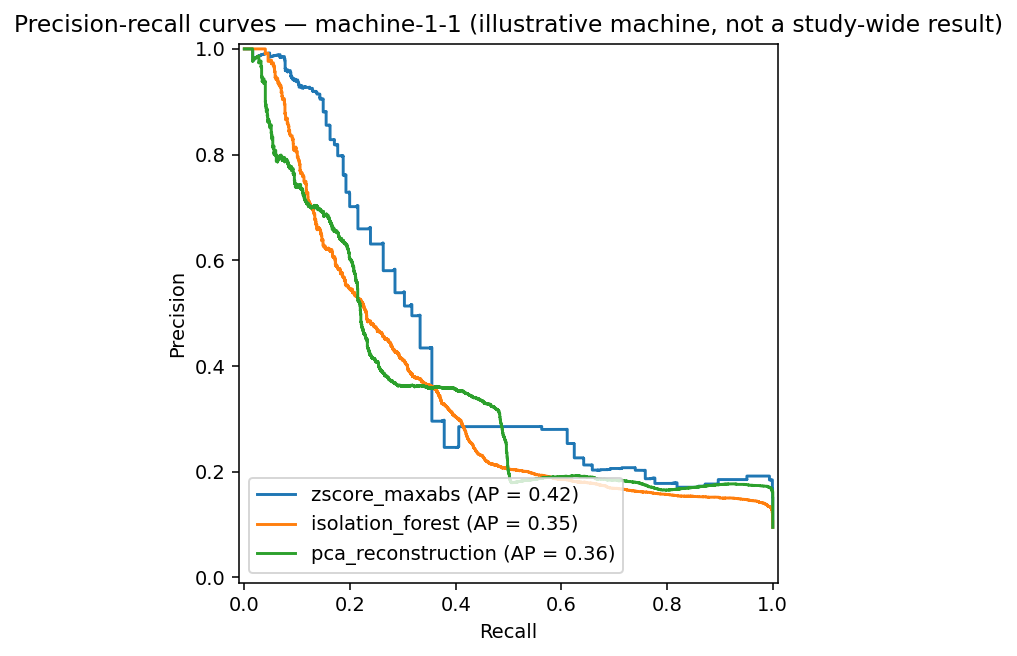

### fig02_confusion_matrices.png

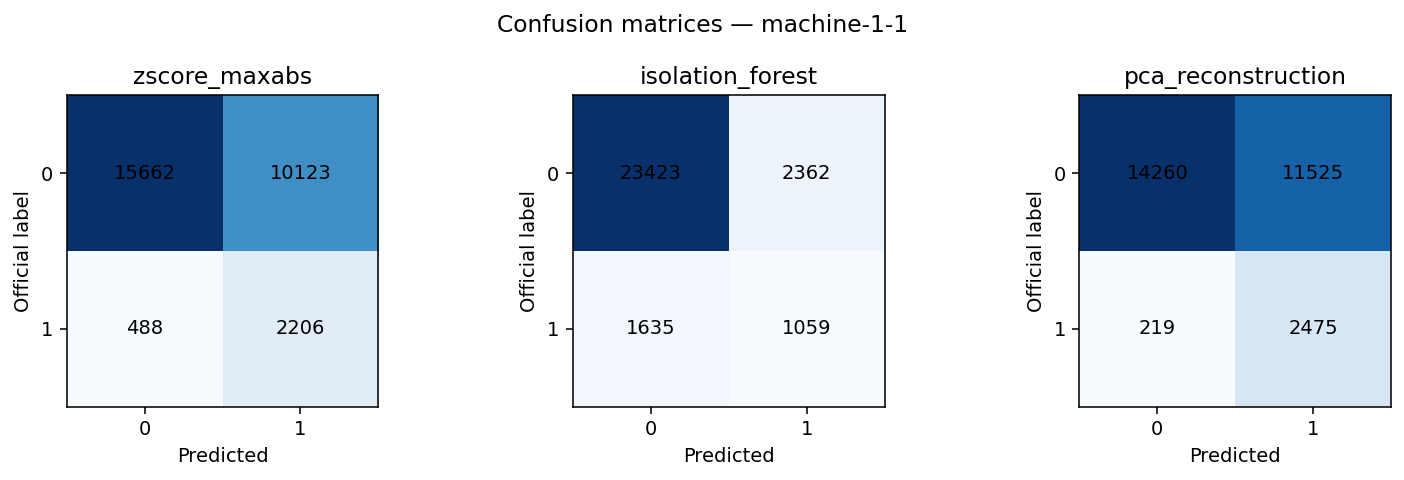

### fig03_metric_comparison.png

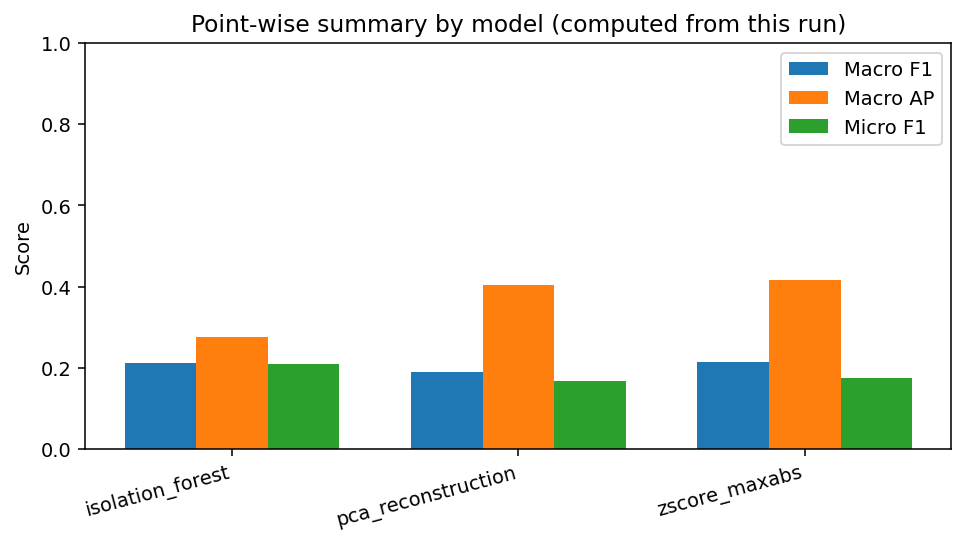

### fig04_per_machine_false_positives.png

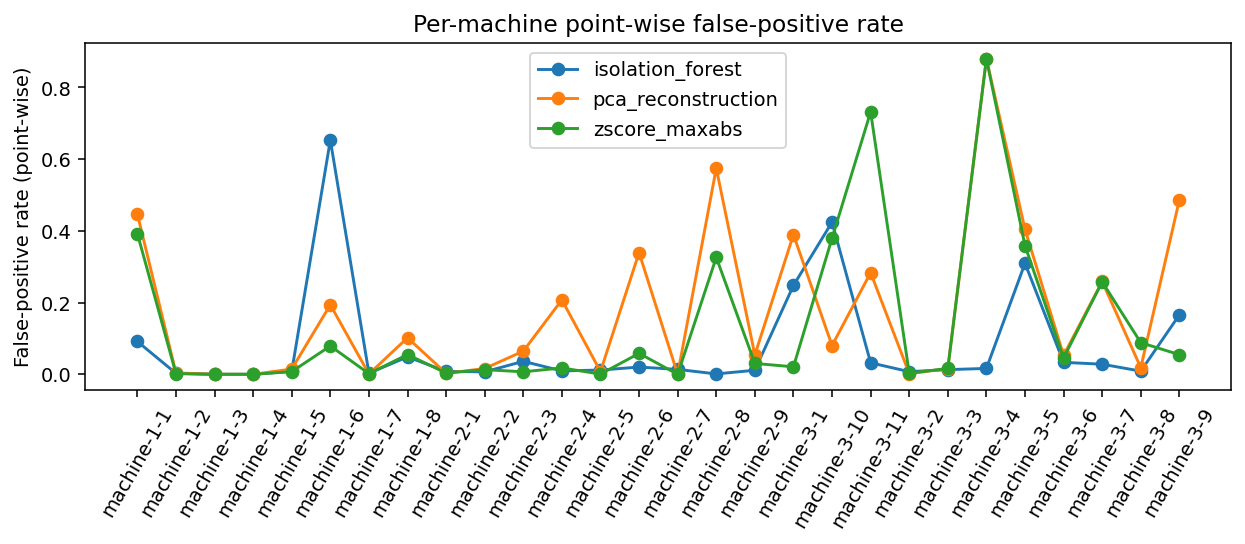

### fig05_sample_metric_traces.png

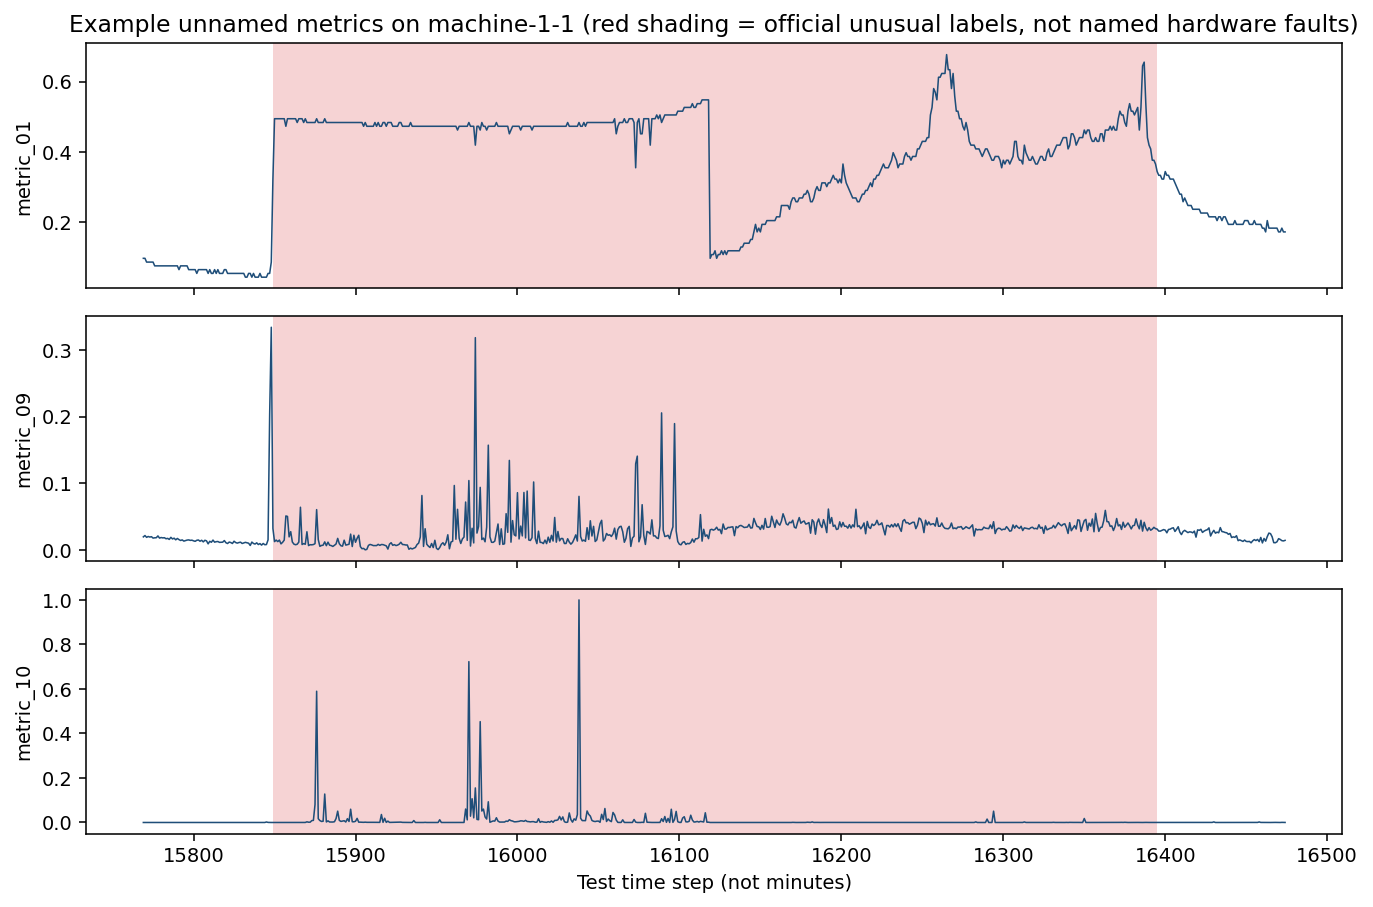

In [7]:
import pandas as pd
from IPython.display import display, Markdown, Image

def show_csv(name):
    path = OUTPUT_DIR / name
    display(Markdown(f"### `{name}`"))
    df = pd.read_csv(path)
    display(df.head(40))
    print("rows:", len(df), "columns:", list(df.columns))

for name in [
    "dataset_inventory.csv",
    "per_machine_results.csv",
    "aggregate_results.csv",
    "episode_metrics.csv",
    "localization_results.csv",
]:
    show_csv(name)

display(Markdown(
    "Average Precision (AP) is scikit-learn’s precision-recall summary. "
    "It is not a trapezoidal ‘area under a drawn curve’ shortcut. "
    "A single AP built by stacking raw scores from every machine together is **not** reported, "
    "because those scores are not on a shared scale."
))

for fig in [
    "fig01_pr_curves.png",
    "fig02_confusion_matrices.png",
    "fig03_metric_comparison.png",
    "fig04_per_machine_false_positives.png",
    "fig05_sample_metric_traces.png",
]:
    fp = OUTPUT_DIR / fig
    if fp.exists():
        display(Markdown(f"### {fig}"))
        display(Image(filename=str(fp)))


In [8]:
if not RUN_TRANSFER:
    print("Optional transfer experiment skipped because RUN_TRANSFER is False.")
    print("The official tables above remain the per-machine protocol only.")
else:
    holdout = [m for m in study_meta["machines_succeeded"] if m.startswith("machine-3-")]
    source = [m for m in study_meta["machines_succeeded"] if m not in holdout]
    if len(source) < 4 or len(holdout) < 1:
        print("Transfer skipped: not enough source/holdout machines in this run.")
        print("source:", source, "holdout:", holdout)
    else:
        print("Transfer source machines:", source)
        print("Transfer holdout machines:", holdout)
        X_fit_parts, X_cal_parts = [], []
        for m in source:
            Xtr = load_numeric_matrix(ROOT / "train" / f"{m}.txt")
            n_fit, n_cal, _ = chronological_fit_cal_split(len(Xtr))
            X_fit_parts.append(Xtr[:n_fit])
            if n_cal:
                X_cal_parts.append(Xtr[n_fit:])
        X_fit_raw = np.vstack(X_fit_parts)
        X_cal_raw = np.vstack(X_cal_parts) if X_cal_parts else X_fit_raw[:0]
        stats = fit_imputer_and_scaler(X_fit_raw)
        from sklearn.preprocessing import StandardScaler
        from sklearn.ensemble import IsolationForest
        X_fit = apply_imputer(X_fit_raw, stats)
        X_cal = apply_imputer(X_cal_raw, stats) if len(X_cal_raw) else X_fit
        scaler = StandardScaler().fit(X_fit)
        X_fit_s, X_cal_s = scaler.transform(X_fit), scaler.transform(X_cal)
        vary = stats["varying"]
        idx = np.where(vary)[0]
        if_model = IsolationForest(n_estimators=100, random_state=SEED, n_jobs=1)
        if_model.fit(X_fit_s[:, idx])
        if_thr = threshold_from_scores(-if_model.score_samples(X_cal_s[:, idx]), "calibration_99_5")
        pca_cal, _ = pca_reconstruct(X_fit_s, X_cal_s, vary)
        pca_thr = threshold_from_scores(pca_cal, "calibration_99_5")
        rows = []
        for m in holdout:
            Xt = apply_imputer(load_numeric_matrix(ROOT / "test" / f"{m}.txt"), stats)
            yt = load_binary_labels(ROOT / "test_label" / f"{m}.txt")
            Xs = scaler.transform(Xt)
            if_scores = -if_model.score_samples(Xs[:, idx])
            pca_scores, _ = pca_reconstruct(X_fit_s, Xs, vary)
            for name, scores, thr in [
                ("transfer_isolation_forest", if_scores, if_thr),
                ("transfer_pca_reconstruction", pca_scores, pca_thr),
            ]:
                pred = (scores > thr).astype(np.int32)
                rec = binary_metrics(yt, pred, scores)
                rec.update({"machine": m, "model": name, "threshold": thr, "protocol": "optional_transfer"})
                rows.append(rec)
        transfer_df = pd.DataFrame(rows)
        transfer_df.to_csv(OUTPUT_DIR / "optional_transfer_results.csv", index=False)
        display(transfer_df)
        print("Wrote outputs/optional_transfer_results.csv (optional; not part of official per-machine tables).")
        import zipfile
        zip_path = OUTPUT_DIR / "aiops_smd_outputs.zip"
        with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as zf:
            for fp in sorted(OUTPUT_DIR.iterdir()):
                if fp.name == "aiops_smd_outputs.zip" or fp.is_dir():
                    continue
                zf.write(fp, arcname=fp.name)


Optional transfer experiment skipped because RUN_TRANSFER is False.
The official tables above remain the per-machine protocol only.


In [9]:
zip_path = OUTPUT_DIR / "aiops_smd_outputs.zip"
print("ZIP path:", zip_path.resolve())
print("ZIP size_bytes:", zip_path.stat().st_size if zip_path.exists() else None)
print("Files in outputs/:")
for p in sorted(OUTPUT_DIR.iterdir()):
    print(f"  {p.name:40} {p.stat().st_size}")

try:
    from google.colab import files
    files.download(str(zip_path))
except Exception as exc:
    print("Automatic browser download is only available inside Google Colab.")
    print("If you are in Colab and this message appears, download outputs/aiops_smd_outputs.zip from the Files pane.")
    print("Detail:", type(exc).__name__, exc)


ZIP path: /content/outputs/aiops_smd_outputs.zip
ZIP size_bytes: 393781
Files in outputs/:
  aggregate_results.csv                    1142
  aiops_smd_outputs.zip                    393781
  dataset_inventory.csv                    5011
  episode_metrics.csv                      7491
  fig01_pr_curves.png                      65394
  fig02_confusion_matrices.png             41407
  fig03_metric_comparison.png              43104
  fig04_per_machine_false_positives.png    118743
  fig05_sample_metric_traces.png           127806
  localization_results.csv                 73139
  metadata.json                            2693
  per_machine_results.csv                  17967
  provenance_manifest.json                 19838


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>